In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
df = pd.read_csv('Raisin_Dataset.csv')

In [3]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [6]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [7]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(900, 8)

In [10]:
df.columns

Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='object')

In [11]:
df.dtypes

,0
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64
Class,object


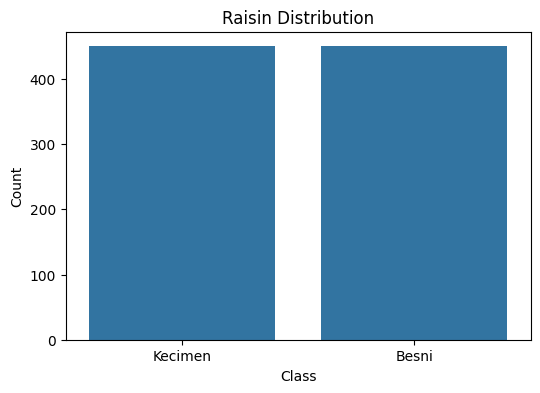

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title("Raisin Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

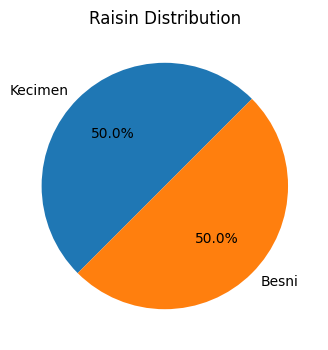

In [13]:
class_counts = df['Class'].value_counts()
plt.figure(figsize=(6,4))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=45)
plt.title('Raisin Distribution')
plt.show()

In [14]:
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
print("Numerical Feature")
print(numerical_features.tolist())

Numerical Feature
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


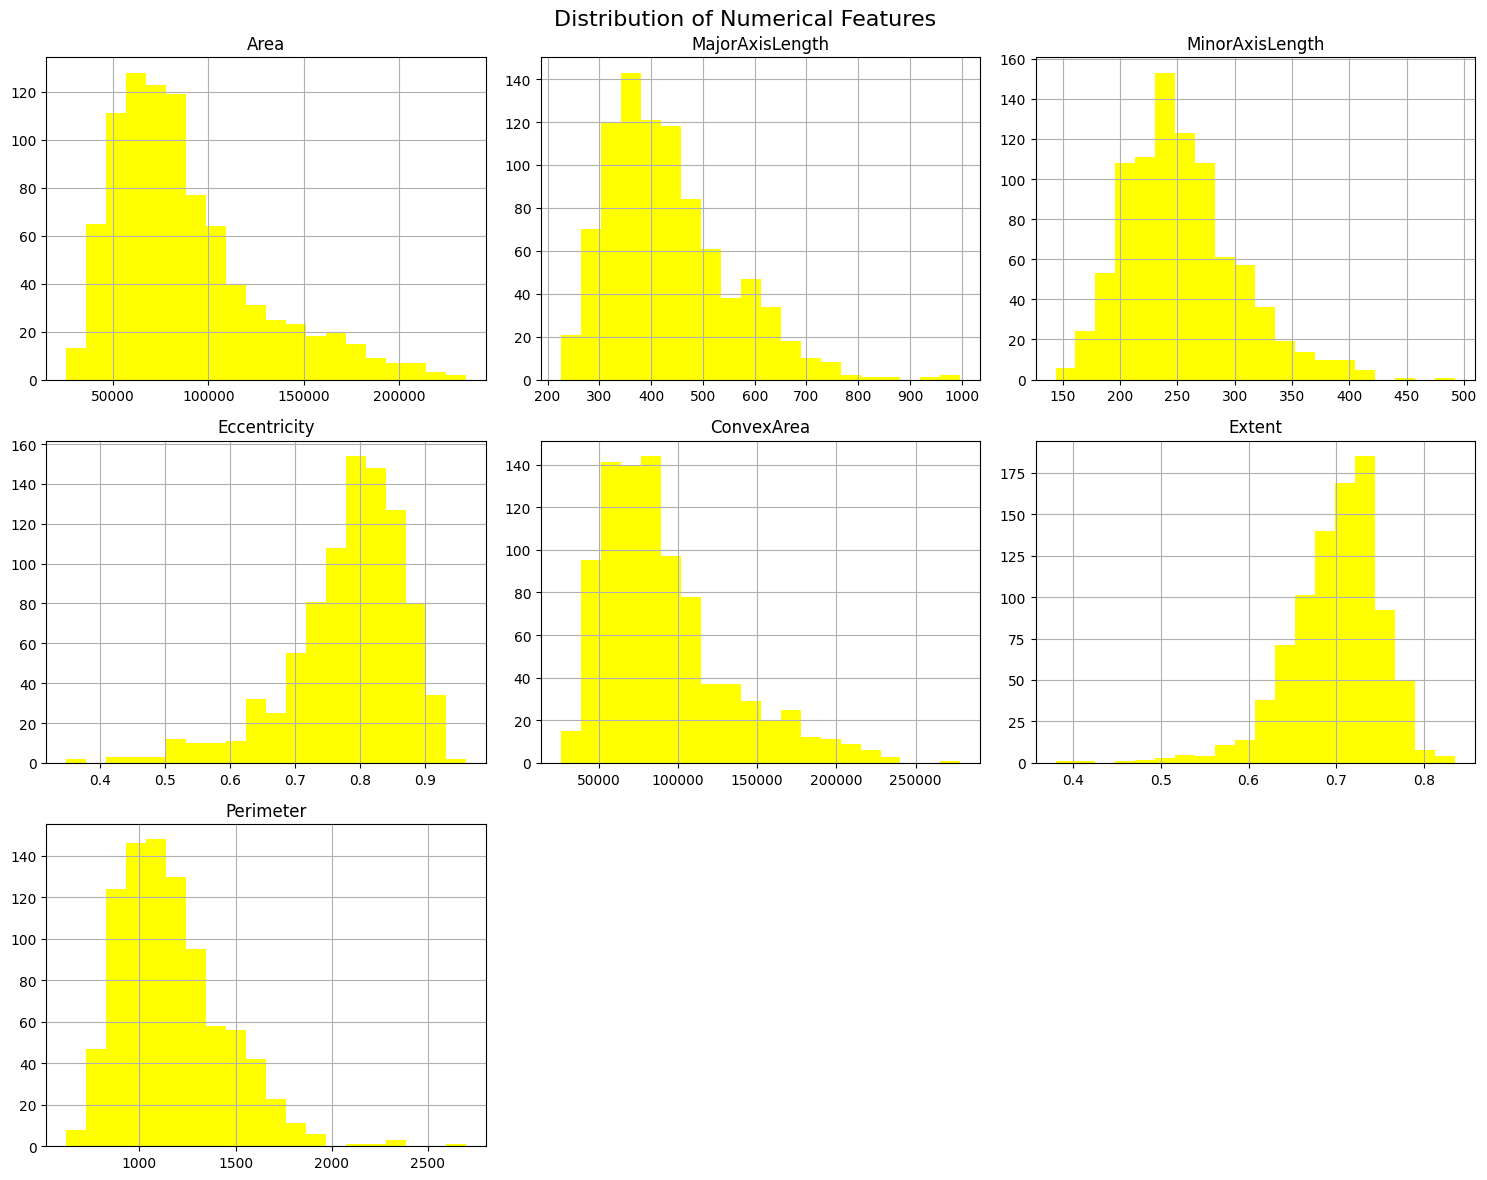

In [15]:
df[numerical_features].hist(figsize=(15,12),bins=20, color='yellow')
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

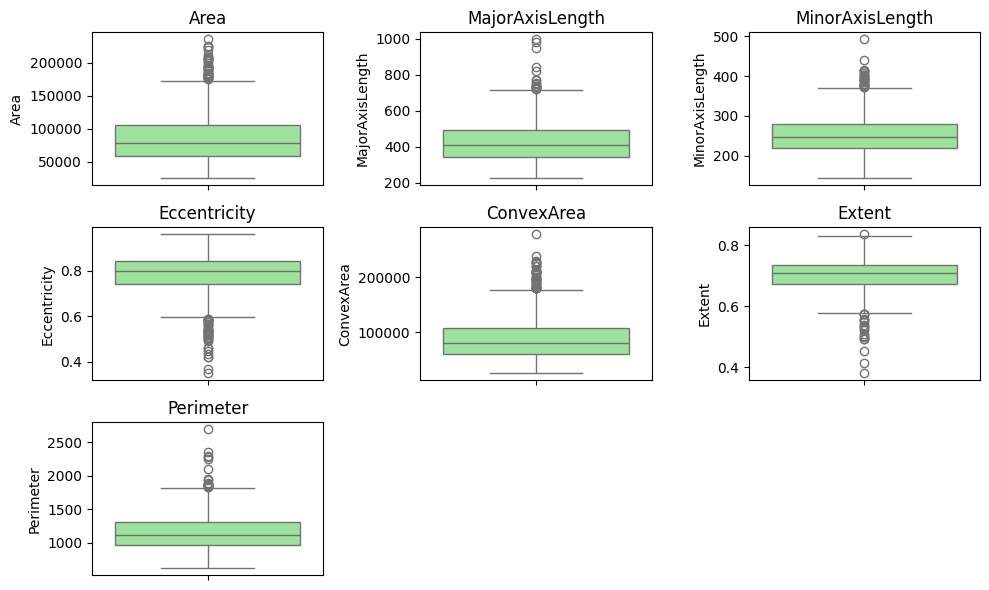

In [16]:
plt.figure(figsize=(10,6))
for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[column],color='lightgreen')
    plt.title(column)
plt.tight_layout()
plt.show()

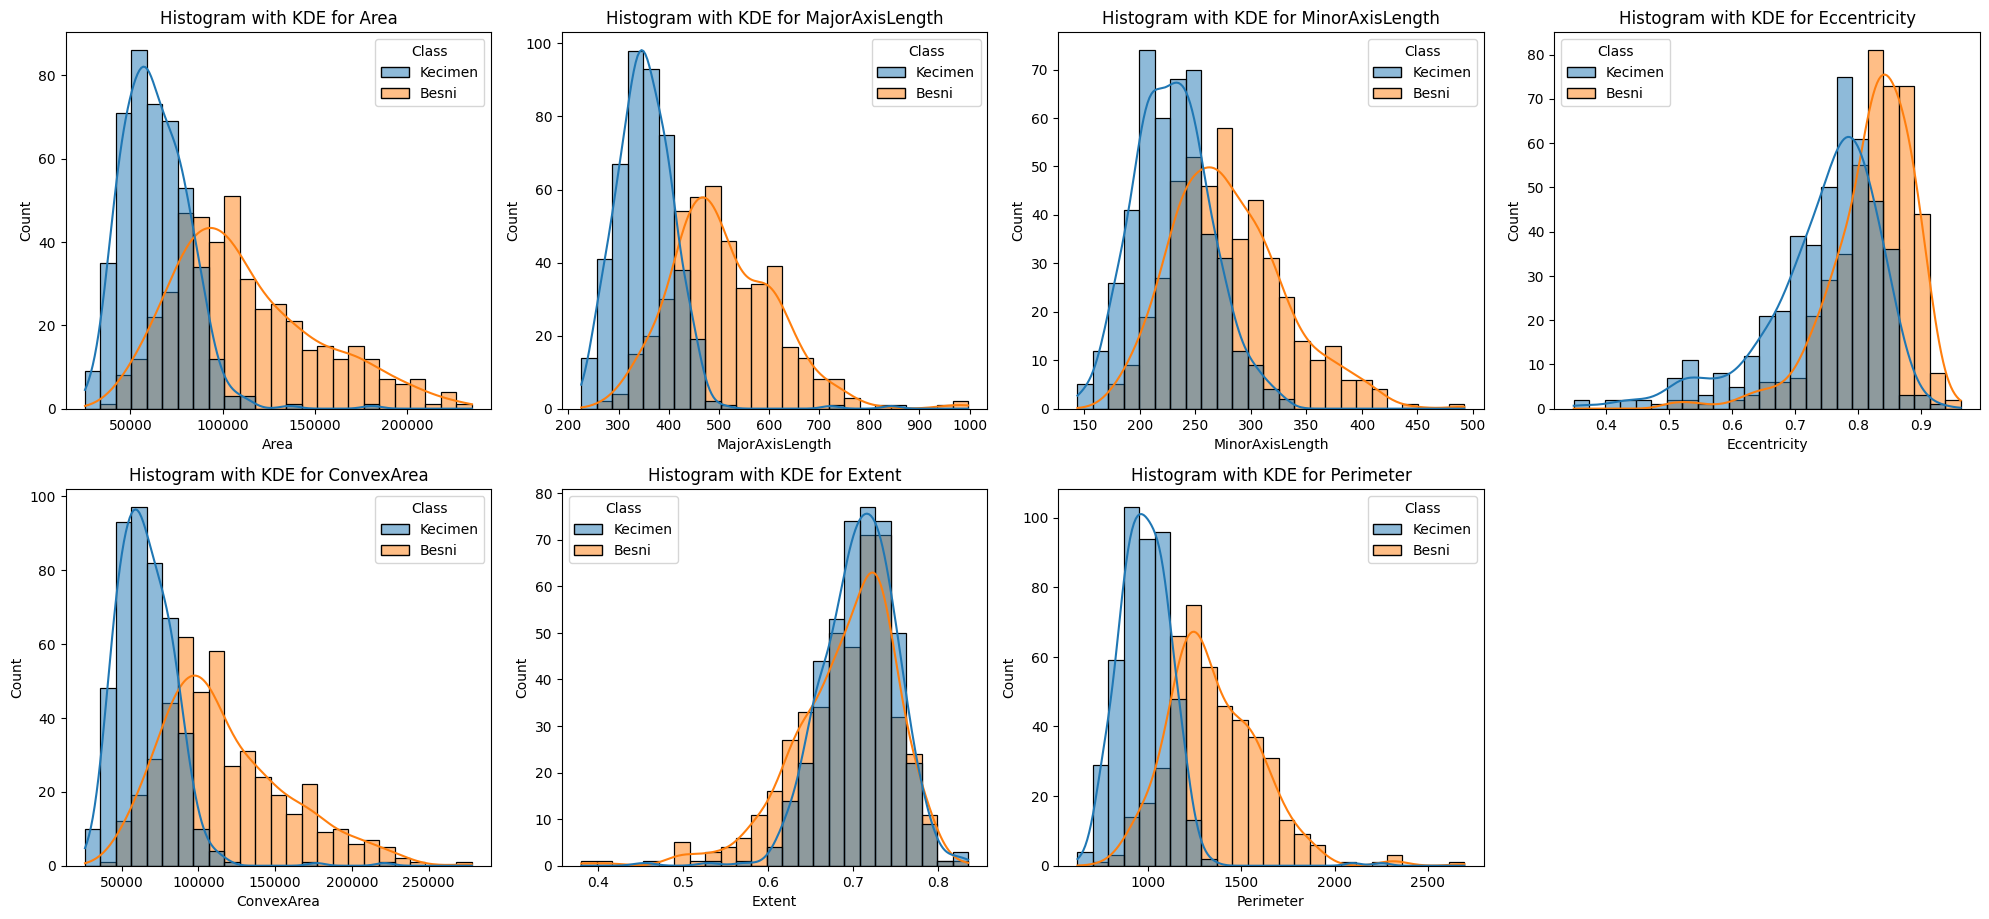

In [20]:
# Side-by-side Histograms with KDE (4 by 4 layout)
import math

cols = 4
rows = 4

fig, axes = plt.subplots(rows, cols, figsize=(20, 18))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    if i < len(axes):
        sns.histplot(data=df, x=column, hue="Class", kde=True, bins=25, ax=axes[i])
        axes[i].set_title(f'Histogram with KDE for {column}')

# Hide any empty subplots in the 4x4 grid
for j in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

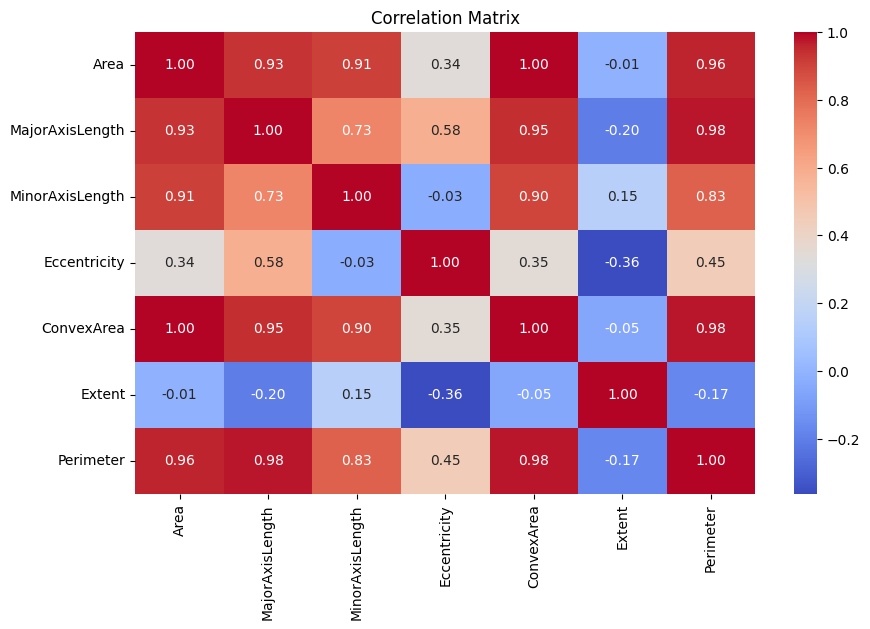

In [ ]:
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

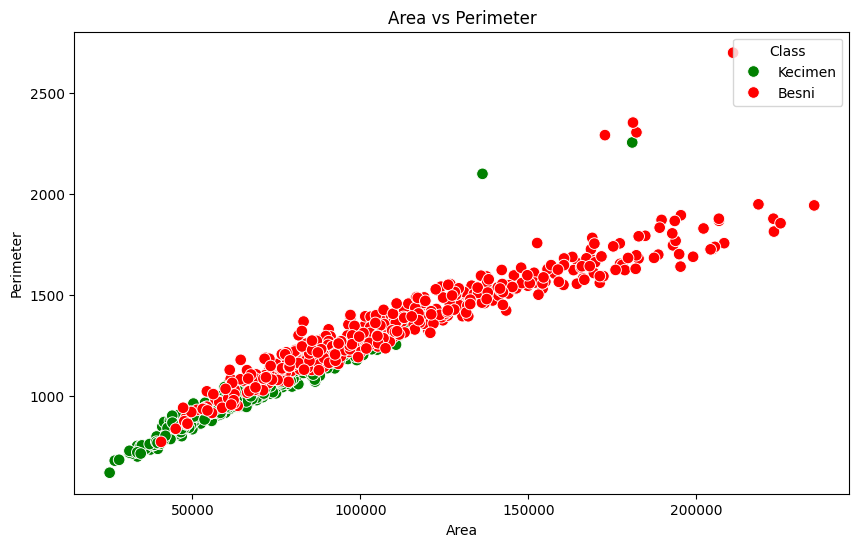

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Area', y='Perimeter', palette={'Kecimen':'Green','Besni':'Red'},hue='Class',s=70)
plt.title("Area vs Perimeter")
plt.show()


In [ ]:
label_encoder = LabelEncoder()

df["Class_encoded"] = label_encoder.fit_transform(df["Class"])
print(df[["Class","Class_encoded"]].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [ ]:
X = df[numerical_features]
y = df["Class_encoded"]

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Samples",X_train.shape[0])
print("Testing Samples",X_test.shape[0])

Training Samples 720
Testing Samples 180


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred = gnb.predict(X_test)
print("Predicted Labels")
print(y_pred)

Predicted Labels
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [ ]:
comparison = pd.DataFrame({'Actual Labels':y_test.values,'Predicted Labels':y_pred})
print(comparison)

     Actual Labels  Predicted Labels
0                0                 1
1                0                 0
2                0                 0
3                1                 1
4                0                 0
..             ...               ...
175              0                 0
176              0                 0
177              0                 1
178              0                 0
179              1                 1

[180 rows x 2 columns]


In [ ]:
comparison = pd.DataFrame({'Actual Labels':y_test.values,'Predicted Labels':y_pred})
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual Labels"])
comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted Labels"])

comparison.head(20)

,Actual Labels,Predicted Labels,Actual_Class,Predicted_Class
0,0,1,Besni,Kecimen
1,0,0,Besni,Besni
2,0,0,Besni,Besni
3,1,1,Kecimen,Kecimen
4,0,0,Besni,Besni
5,1,1,Kecimen,Kecimen
6,0,0,Besni,Besni
7,1,1,Kecimen,Kecimen
8,1,1,Kecimen,Kecimen
9,1,1,Kecimen,Kecimen


In [ ]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)


Accuracy: 0.8166666666666667


In [ ]:
precision = precision_score(y_test,y_pred,average='weighted')
print("Precision:",precision)

Precision: 0.8387927618544444


In [ ]:
recall = recall_score(y_test,y_pred,average='weighted')
print("Recall:",recall)

Recall: 0.8166666666666667


In [ ]:
f1 = f1_score(y_test,y_pred)
print("F1 Score:",f1)

F1 Score: 0.8374384236453202


In [ ]:
print("Classification Report")
print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))

Classification Report
              precision    recall  f1-score   support

       Besni       0.93      0.69      0.79        90
     Kecimen       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



In [ ]:
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix")
print(cm)

Confusion Matrix
[[62 28]
 [ 5 85]]


In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8263888888888888
Testing Accuracy: 0.8166666666666667
